# Testing Lipschitz Libraries

In this notebook we will test the Lipschitz libraries deel-lip and monotonicnetworks on a simple regression problem for amplitude estimation.

## Data processing

The data used for this part of the analysis is the same the tutorials for Modern ML for LHC, regression modules. The data describes a 
$$
gg \rightarrow \gamma \gamma g
$$
process. 

In [1]:
import os
import sys
import random
import numpy as np

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import tqdm

import monotonicnetworks as lmn

import matplotlib.pyplot as plt

# "Homemade" modules
from models import UnconstrainedModel, LipschitzModel
from train_eval import train, evaluate, predict, fit_many


In [2]:
# Data loading
# The data is not part of the repository: it is expected in a directory (or a symlink to one) called
# tutorial-2-data at the top level of the repository, i.e. one level above this notebook
DATA_DIR = os.path.join("..", "tutorial-2-data")

trn_dat = np.load(os.path.join(DATA_DIR, "trn_dat.npy"))
trn_amp = np.load(os.path.join(DATA_DIR, "trn_amp.npy"))

val_dat = np.load(os.path.join(DATA_DIR, "val_dat.npy"))
val_amp = np.load(os.path.join(DATA_DIR, "val_amp.npy"))

tst_dat = np.load(os.path.join(DATA_DIR, "tst_dat.npy"))
tst_amp = np.load(os.path.join(DATA_DIR, "tst_amp.npy"))

In [3]:
print(f"train data shape: {trn_dat.shape}")
print(f"train amp  shape: {trn_amp.shape}")
print(f"test  data shape: {tst_dat.shape}")
print(f"test  amp  shape: {tst_amp.shape}")
print(f"val   data shape: {val_dat.shape}")
print(f"val   amp  shape: {val_amp.shape}")

train data shape: (30000, 5, 4)
train amp  shape: (30000,)
test  data shape: (30000, 5, 4)
test  amp  shape: (30000,)
val   data shape: (30000, 5, 4)
val   amp  shape: (30000,)


The data is organized with 30 000 samples, where each sample contain 5 particles, each with 4 kinematic features. The target is the amplitude of the process, described by a single number.

## Visualization of the data

In [4]:
# utility functions for the data visualization
def get_init_pz(events):
    # Initial particle z-momentum
    return events[:, 0, 3] + events[:, 1, 3]

def get_mass(fv):
    # Invariant mass of a 4-vector
    msq = np.round(fv[:, 0]**2 - fv[:, 1]**2 - fv[:, 2]**2 - fv[:, 3]**2, 5)
    if (msq < 0.).any():
       raise Exception("mass squared is less than zero")
    return np.sqrt(msq)
    #return msq

def get_pt(fv):
    # Transverse momentum of a four vector
    ptsq = np.round(fv[:, 1]**2 + fv[:, 2]**2, 5)
    return np.sqrt(ptsq)

def get_met():
    # Missing transverse energy of a vector
    return np.abs(np.sum(fv[:, :, 1]+fv[:, :, 2], axis=1))

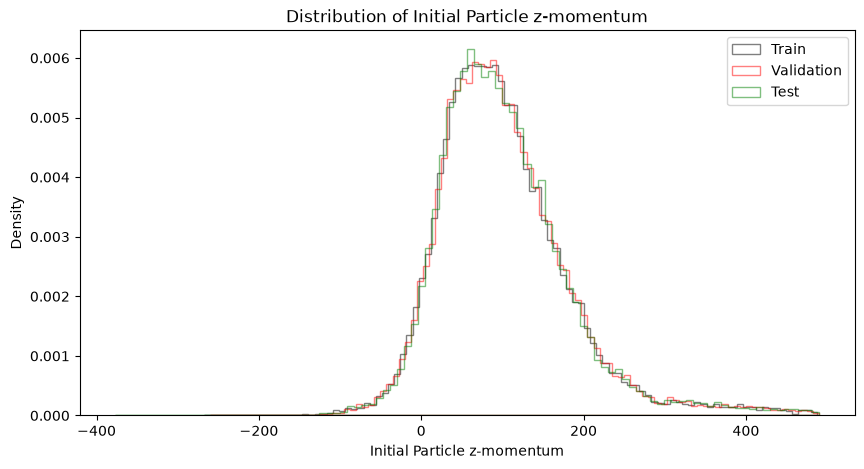

In [5]:
# Visualizing the initial pz distributions
train_pz = get_init_pz(trn_dat)
val_pz = get_init_pz(val_dat)
test_pz = get_init_pz(tst_dat)

plt.figure(figsize=(10, 5))
plt.hist(train_pz, bins=100, alpha=0.5, label='Train', density=True, histtype='stepfilled', fill=None)
plt.hist(val_pz, bins=100, alpha=0.5, label='Validation', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.hist(test_pz, bins=100, alpha=0.5, label='Test', density=True, histtype='stepfilled', fill=None, edgecolor='green')
plt.xlabel('Initial Particle z-momentum')
plt.ylabel('Density')
plt.title('Distribution of Initial Particle z-momentum')
plt.legend()

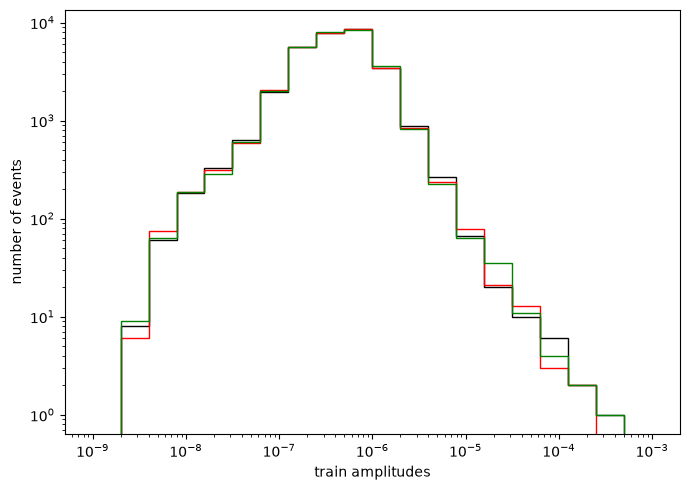

In [6]:
# Amplitudes
fig, axs = plt.subplots(1, 1, figsize=(7,5))
bins=np.logspace(-9, -3, 21)

axs.hist(trn_amp, histtype='stepfilled', fill=None, bins=bins)
axs.hist(val_amp, histtype='stepfilled', fill=None, bins=bins, edgecolor='red')
axs.hist(tst_amp, histtype='stepfilled', fill=None, bins=bins, edgecolor='green')

axs.set_yscale('log')
axs.set_xscale('log')

axs.set_xlabel("train amplitudes")
axs.set_ylabel("number of events")

fig.tight_layout()


We have verified that the data is likely distributed the same for the different datasets. This is important for training and validation. Next step is to scale the data to make it easier for the neural network to learn and to make the bounds for the Lipschitz constant easier to handle.

## Preprocessing

First, we flatten the data. We want the neural network to take as input a vector of length 20, corresponding to the 5 particles, each with 4 kinematic features. At this point we do not care about Lorentz invariance or permutation invariance.

In [7]:
# Flattening all particle kinematics into a single event vector
trn_data_flat = trn_dat.reshape(trn_dat.shape[0], -1)
val_data_flat = val_dat.reshape(val_dat.shape[0], -1)
tst_data_flat = tst_dat.reshape(tst_dat.shape[0], -1)

In [8]:
print(f"train data shape: {trn_data_flat.shape}")
print(f"validation data shape: {val_data_flat.shape}")
print(f"test data shape: {tst_data_flat.shape}")

train data shape: (30000, 20)
validation data shape: (30000, 20)
test data shape: (30000, 20)


In [9]:
# Standardize using sklean's StandardScaler
from sklearn.preprocessing import StandardScaler

# Scaling the kinematics
scaler = StandardScaler().fit(trn_data_flat)

trn_data_scaled = scaler.transform(trn_data_flat)
val_data_scaled = scaler.transform(val_data_flat)
tst_data_scaled = scaler.transform(tst_data_flat)

# Scaling the amplitudes -> The standard scaler leaves the large outliers, which is not ideal here


# Other possibility is logscaling
trn_amp_log_scaled = np.log(trn_amp.reshape(-1, 1))
val_amp_log_scaled = np.log(val_amp.reshape(-1, 1))
tst_amp_log_scaled = np.log(tst_amp.reshape(-1, 1))


amp_scaler = StandardScaler().fit(trn_amp_log_scaled)  # Fit the scaler on the log-scaled amplitudes
trn_amp_scaled = amp_scaler.transform(trn_amp_log_scaled)
val_amp_scaled = amp_scaler.transform(val_amp_log_scaled)
tst_amp_scaled = amp_scaler.transform(tst_amp_log_scaled)

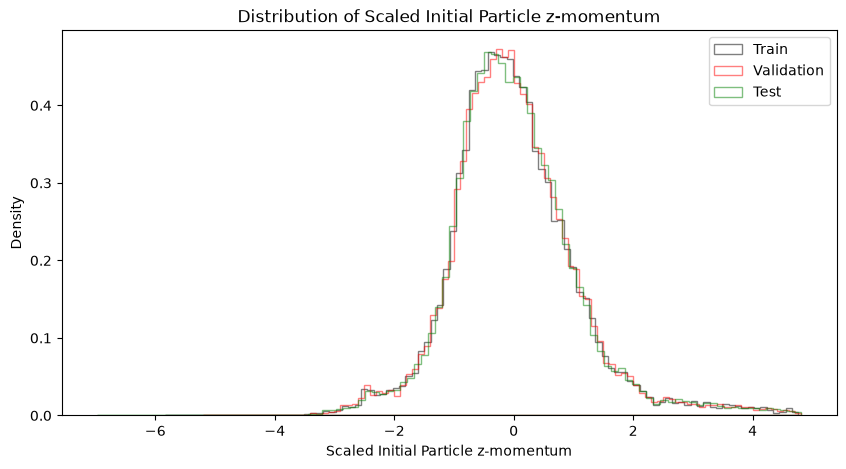

In [10]:
# Plotting the pz of the first two gluons after scaling
def get_scaled_pz(events_scaled):
    # Get the scaled z-momentum of the first two particles
    #print(f"Scaled events shape: {events_scaled.shape}")
    reshaped = events_scaled.reshape(events_scaled.shape[0], 5, 4)
    #print(f"Reshaped events shape: {reshaped.shape}")
    return reshaped[:, 0, 3] + reshaped[:, 1, 3]

train_scaled_pz = get_scaled_pz(trn_data_scaled)
val_scaled_pz = get_scaled_pz(val_data_scaled)
test_scaled_pz = get_scaled_pz(tst_data_scaled)

plt.figure(figsize=(10, 5))
plt.hist(train_scaled_pz, bins=100, alpha=0.5, label='Train', density=True, histtype='stepfilled', fill=None)
plt.hist(val_scaled_pz, bins=100, alpha=0.5, label='Validation', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.hist(test_scaled_pz, bins=100, alpha=0.5, label='Test', density=True, histtype='stepfilled', fill=None, edgecolor='green')
plt.xlabel('Scaled Initial Particle z-momentum')
plt.ylabel('Density')
plt.title('Distribution of Scaled Initial Particle z-momentum')
plt.legend()
plt.show()

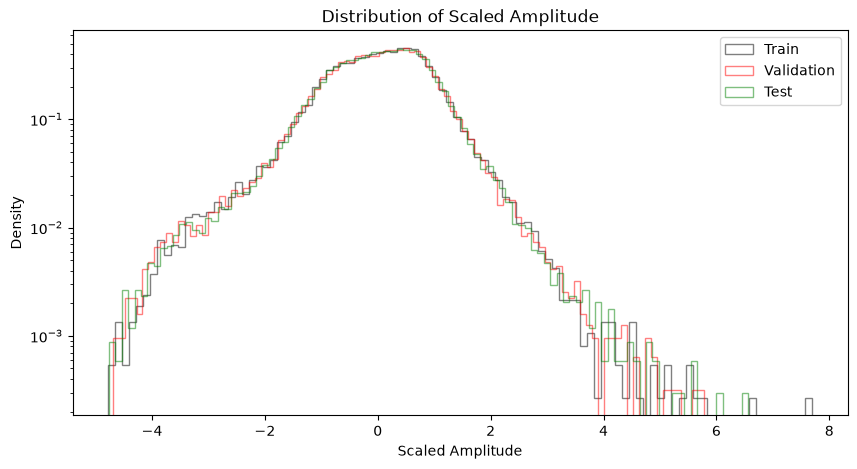

In [11]:
# Checking scaled amplitudes
plt.figure(figsize=(10, 5))
plt.hist(trn_amp_scaled, bins=100, alpha=0.5, label='Train', density=True, histtype='stepfilled', fill=None)
plt.hist(val_amp_scaled, bins=100, alpha=0.5, label='Validation', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.hist(tst_amp_scaled, bins=100, alpha=0.5, label='Test', density=True, histtype='stepfilled', fill=None, edgecolor='green')
plt.xlabel('Scaled Amplitude')
plt.ylabel('Density')
plt.yscale('log')
plt.title('Distribution of Scaled Amplitude')
plt.legend()
plt.show()

## Constructing the dataset objects

In [12]:
class amp_dataset(Dataset):
    def __init__(self, data, amplitudes):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.amplitudes = torch.tensor(amplitudes, dtype=torch.float32)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx], self.amplitudes[idx]

In [13]:
# Preparing the dataset objects
trn_dataset = amp_dataset(trn_data_scaled, trn_amp_log_scaled)
val_dataset = amp_dataset(val_data_scaled, val_amp_log_scaled)
test_dataset = amp_dataset(tst_data_scaled, tst_amp_log_scaled)

# Preparing the dataloaders
SEED = 42 # Setting seeds for reproducibility
BATCH_SIZE = 64
random.seed(SEED)
torch.manual_seed(SEED)

generator = torch.Generator() # Setting the seeded RNG for the dataloaders
generator.manual_seed(SEED)

trn_loader = DataLoader(trn_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generator)

# The evaluation loaders use a large batch size: the result is the same, but evaluating after every epoch gets much cheaper
EVAL_BATCH_SIZE = 4096
trn_eval_loader = DataLoader(trn_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False) # Training data, only for computing the training loss
val_loader = DataLoader(val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False)

# Mean of the training targets, used as the initial value of the output bias of the networks.
# The log-amplitudes sit at ~ -14.7 +- 1, and without this the Lipschitz networks spend most of the training
# slowly moving their biases towards this offset
TRN_AMP_MEAN = float(trn_amp_log_scaled.mean())

# Plain tensors for the parallel sweeps (fit_many)
trn_tensors = (trn_dataset.data, trn_dataset.amplitudes)
val_tensors = (val_dataset.data, val_dataset.amplitudes)
test_tensors = (test_dataset.data, test_dataset.amplitudes)

In [14]:
print("Training dataset length:", len(trn_dataset))
print("Validation dataset length:", len(val_dataset))
print("Test dataset length:", len(test_dataset))

X_train, y_train = next(iter(trn_loader))
print("Shape of a batch of training data:", X_train.shape)
print("Shape of a batch of training amplitudes:", y_train.shape)
print("First batch of training data:", X_train)

Training dataset length: 30000
Validation dataset length: 30000
Test dataset length: 30000
Shape of a batch of training data: torch.Size([64, 20])
Shape of a batch of training amplitudes: torch.Size([64, 1])
First batch of training data: tensor([[ 0.4493, -0.0058, -0.0058,  ...,  0.2075, -0.4071,  0.4235],
        [ 2.6225, -0.0058, -0.0058,  ...,  1.5080,  1.2574,  0.9323],
        [-0.3639, -0.0058, -0.0058,  ...,  1.8867, -0.2163, -0.0900],
        ...,
        [-1.3239, -0.0058, -0.0058,  ..., -0.5316, -0.3449, -0.4189],
        [-0.2828, -0.0058, -0.0058,  ..., -0.2261, -0.6096,  0.8008],
        [-0.9081, -0.0058, -0.0058,  ..., -0.4744,  0.2549,  0.0041]])


In [15]:
# UnconstrainedModel and LipschitzModel are defined in models.py (imported at the top of the notebook)
print(LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=64, output_dim=1))

LipschitzModel(
  (layers): Sequential(
    (0): ParametrizedLinear(
      in_features=20, out_features=64, bias=True
      (parametrizations): ModuleDict(
        (weight): ParametrizationList(
          (0): Normalize()
        )
      )
    )
    (1): GroupSort(num_groups: 2)
    (2): ParametrizedLinear(
      in_features=64, out_features=64, bias=True
      (parametrizations): ModuleDict(
        (weight): ParametrizationList(
          (0): Normalize()
        )
      )
    )
    (3): GroupSort(num_groups: 2)
    (4): ParametrizedLinear(
      in_features=64, out_features=1, bias=True
      (parametrizations): ModuleDict(
        (weight): ParametrizationList(
          (0): Normalize()
        )
      )
    )
  )
)


## Model Training

In [16]:
device = "cuda" if torch.cuda.is_available() else "cpu" # To utilise the best available computing resources

LEARNING_RATE = 0.001
HIDDEN_DIM = 64

# Lipschitz Models
Lipschitz_1_model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=1.0, output_bias_init=TRN_AMP_MEAN).to(device)
Lipschitz_2_model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=2.0, output_bias_init=TRN_AMP_MEAN).to(device)
Lipschitz_5_model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=5.0, output_bias_init=TRN_AMP_MEAN).to(device)

#Unconstrained model
Unconstrained_model = UnconstrainedModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, output_bias_init=TRN_AMP_MEAN).to(device)

# Optimizers and loss functions
optimizer_Lipschitz_1 = torch.optim.Adam(Lipschitz_1_model.parameters(), lr=LEARNING_RATE)
optimizer_Lipschitz_2 = torch.optim.Adam(Lipschitz_2_model.parameters(), lr=LEARNING_RATE)
optimizer_Lipschitz_5 = torch.optim.Adam(Lipschitz_5_model.parameters(), lr=LEARNING_RATE)
optimizer_Unconstrained = torch.optim.Adam(Unconstrained_model.parameters(), lr=LEARNING_RATE)

loss_fn = nn.MSELoss()



In [17]:
# Training
NUM_EPOCHS = 15
train_losses_L1, val_losses_L1 = train(model =Lipschitz_1_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    train_eval_loader = trn_eval_loader,
    optimizer = optimizer_Lipschitz_1,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = NUM_EPOCHS, # No early stopping
    device = device)

train_losses_L2, val_losses_L2 = train(model =Lipschitz_2_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    train_eval_loader = trn_eval_loader,
    optimizer = optimizer_Lipschitz_2,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = NUM_EPOCHS, # No early stopping
    device = device)

train_losses_L5, val_losses_L5 = train(model =Lipschitz_5_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    train_eval_loader = trn_eval_loader,
    optimizer = optimizer_Lipschitz_5,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = NUM_EPOCHS, # No early stopping
    device = device)

train_losses_Unconstrained, val_losses_Unconstrained = train(model =Unconstrained_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    train_eval_loader = trn_eval_loader,
    optimizer = optimizer_Unconstrained,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    max_iter = NUM_EPOCHS, # No early stopping
    device = device)



Epoch 1: Train Loss: 0.5670, Val Loss: 0.5389
Epoch 15: Train Loss: 0.0826, Val Loss: 0.0834
Epoch 1: Train Loss: 0.5445, Val Loss: 0.5009
Epoch 15: Train Loss: 0.0816, Val Loss: 0.0763
Epoch 1: Train Loss: 0.4748, Val Loss: 0.2270
Epoch 15: Train Loss: 0.0515, Val Loss: 0.0374
Epoch 1: Train Loss: 0.3883, Val Loss: 0.1157
Epoch 15: Train Loss: 0.0087, Val Loss: 0.0103


### Training time comparison
A short timing test of the unconstrained and the Lipschitz model, using fresh models with the same architecture and optimizer settings as above. The time per epoch is split into the training pass and the evaluation of the training and validation loss.

In [18]:
import time
from train_eval import train_epoch

TIMING_EPOCHS = 5 # Number of timed epochs (after one warm-up epoch)

def time_epochs(model, num_epochs=TIMING_EPOCHS):
    # Returns the average time per epoch (in seconds) of the training pass and of the loss evaluation
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    def timed(func):
        start = time.perf_counter()
        func()
        if device == "cuda":
            torch.cuda.synchronize() # Wait for the GPU to finish before stopping the clock
        return time.perf_counter() - start

    def training_pass():
        train_epoch(model, trn_loader, optimizer, loss_fn, device)

    def evaluation_pass():
        evaluate(model, trn_eval_loader, loss_fn, device)
        evaluate(model, val_loader, loss_fn, device)

    training_pass() # Warm-up epoch, not timed
    train_time = sum(timed(training_pass) for _ in range(num_epochs)) / num_epochs
    eval_time = sum(timed(evaluation_pass) for _ in range(num_epochs)) / num_epochs
    return train_time, eval_time

timing_models = {
    "Unconstrained": UnconstrainedModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, output_bias_init=TRN_AMP_MEAN).to(device),
    "Lipschitz": LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=1.0, output_bias_init=TRN_AMP_MEAN).to(device),
}
timings = {name: time_epochs(model) for name, model in timing_models.items()}

print(f"{'Model':<15}{'Training [s]':>14}{'Evaluation [s]':>16}{'Total [s]':>12}")
for name, (train_time, eval_time) in timings.items():
    print(f"{name:<15}{train_time:>14.3f}{eval_time:>16.3f}{train_time + eval_time:>12.3f}")

ratio_train = timings["Lipschitz"][0] / timings["Unconstrained"][0]
ratio_total = sum(timings["Lipschitz"]) / sum(timings["Unconstrained"])
print(f"\nLipschitz / Unconstrained time per epoch: {ratio_train:.2f}x (training pass), {ratio_total:.2f}x (total)")

Model            Training [s]  Evaluation [s]   Total [s]
Unconstrained           0.274           0.334       0.608
Lipschitz               0.584           0.385       0.969

Lipschitz / Unconstrained time per epoch: 2.13x (training pass), 1.59x (total)


### Effect of the output bias initialization on the training time
The original Lipschitz model started with its output bias at zero, the current one starts at the mean of the training targets. The initialization does not change the cost of an epoch, so the gain is in how many epochs (and thereby how much time) the training needs to reach a given loss. Both versions are trained here from the same seed, tracking the validation loss against the accumulated training time.

Model                       Time per epoch [s]  Final val loss
Original (bias at zero)                  0.526          0.5210
Bias at target mean                      0.538          0.0492

Original: best validation loss 0.5210 after 30 epochs (15.8 s)
With the bias at the target mean this loss is reached after 2 epochs (1.0 s): 15.4x faster


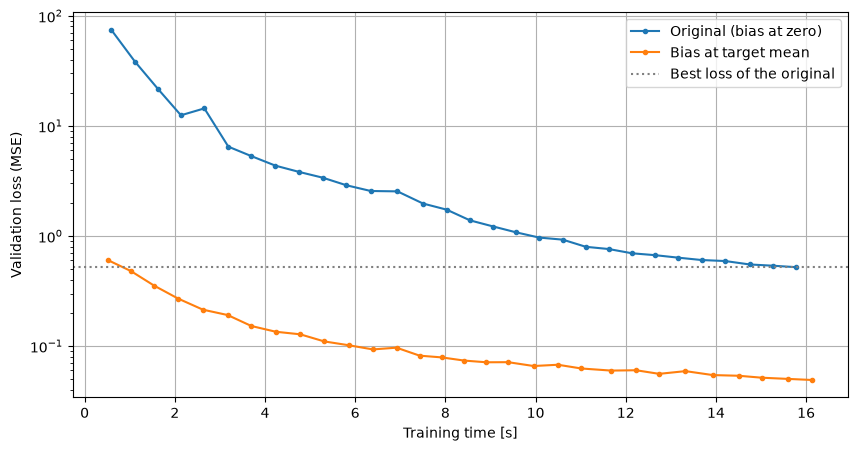

In [19]:
import time
from train_eval import train_epoch

CONVERGENCE_EPOCHS = 30

def train_with_clock(model, num_epochs=CONVERGENCE_EPOCHS):
    # Returns the accumulated training time (excluding the evaluation) and the validation loss after every epoch
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    elapsed = 0.0
    times, losses = [], []
    for _ in range(num_epochs):
        start = time.perf_counter()
        train_epoch(model, trn_loader, optimizer, loss_fn, device)
        if device == "cuda":
            torch.cuda.synchronize() # Wait for the GPU to finish before stopping the clock
        elapsed += time.perf_counter() - start
        times.append(elapsed)
        losses.append(evaluate(model, val_loader, loss_fn, device))
    return np.array(times), np.array(losses)

convergence = {}
for name, bias_init in [("Original (bias at zero)", None), ("Bias at target mean", TRN_AMP_MEAN)]:
    torch.manual_seed(SEED) # Same initial weights for both versions
    model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=1.0, output_bias_init=bias_init).to(device)
    convergence[name] = train_with_clock(model)

times_orig, losses_orig = convergence["Original (bias at zero)"]
times_init, losses_init = convergence["Bias at target mean"]

print(f"{'Model':<26}{'Time per epoch [s]':>20}{'Final val loss':>16}")
for name, (times, losses) in convergence.items():
    print(f"{name:<26}{times[-1] / len(times):>20.3f}{losses[-1]:>16.4f}")

# Time the new version needs to reach the best loss the original version gets to
target = losses_orig.min()
epoch_orig = int(np.argmin(losses_orig))
reached = np.nonzero(losses_init <= target)[0]
print(f"\nOriginal: best validation loss {target:.4f} after {epoch_orig + 1} epochs ({times_orig[epoch_orig]:.1f} s)")
if len(reached) > 0:
    print(f"With the bias at the target mean this loss is reached after {reached[0] + 1} epochs ({times_init[reached[0]]:.1f} s): "
          f"{times_orig[epoch_orig] / times_init[reached[0]]:.1f}x faster")
else:
    print("With the bias at the target mean this loss is not reached")

plt.figure(figsize=(10, 5))
plt.plot(times_orig, losses_orig, 'o-', markersize=3, label='Original (bias at zero)')
plt.plot(times_init, losses_init, 'o-', markersize=3, label='Bias at target mean')
plt.axhline(target, color='gray', linestyle=':', label='Best loss of the original')
plt.xlabel('Training time [s]')
plt.ylabel('Validation loss (MSE)')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

## Performance evaluation

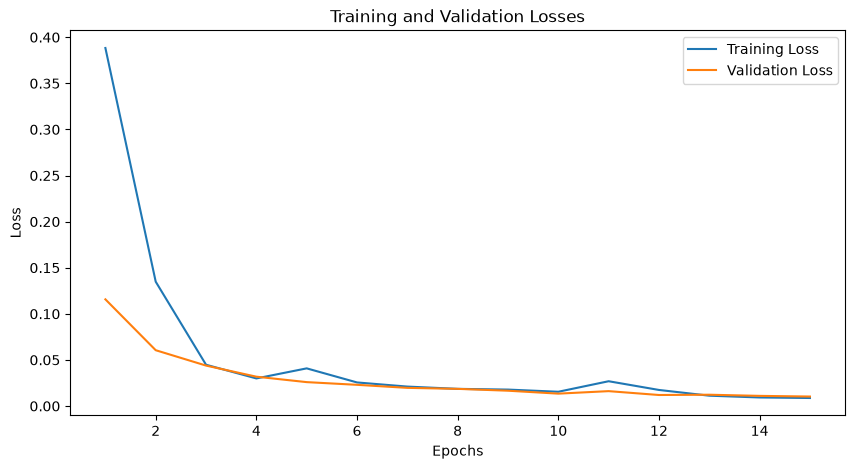

In [20]:
# Plotting the training and validation losses
plt.figure(figsize=(10, 5))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses_Unconstrained, label='Training Loss')
plt.plot(range(1, NUM_EPOCHS + 1), val_losses_Unconstrained, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Losses')
plt.legend()

In [21]:
L1_predictions = predict(Lipschitz_1_model, test_loader, device=device)
L2_predictions = predict(Lipschitz_2_model, test_loader, device=device)
L5_predictions = predict(Lipschitz_5_model, test_loader, device=device)
Unconstrained_predictions = predict(Unconstrained_model, test_loader, device=device)

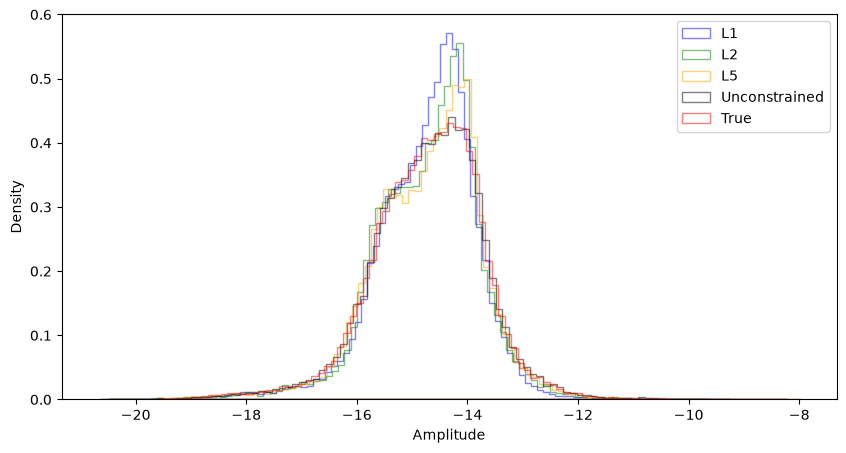

In [22]:
# Plotting the predicted vs true amplitudes for the Lipschitz model
plt.figure(figsize=(10, 5))
plt.hist(L1_predictions, bins=100, alpha=0.5, label='L1', density=True, histtype='stepfilled', fill=None, edgecolor='blue')
plt.hist(L2_predictions, bins=100, alpha=0.5, label='L2', density=True, histtype='stepfilled', fill=None, edgecolor='green')
plt.hist(L5_predictions, bins=100, alpha=0.5, label='L5', density=True, histtype='stepfilled', fill=None, edgecolor='orange')
plt.hist(Unconstrained_predictions, bins=100, alpha=0.5, label='Unconstrained', density=True, histtype='stepfilled', fill=None, edgecolor='black')
plt.hist(tst_amp_log_scaled, bins=100, alpha=0.5, label='True', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.xlabel('Amplitude')
plt.ylabel('Density')
#plt.title('Predicted vs True Amplitudes for Lipschitz Model')
plt.legend()
plt.savefig('Plots/Initial_lipNN_test.pdf')

plt.show()

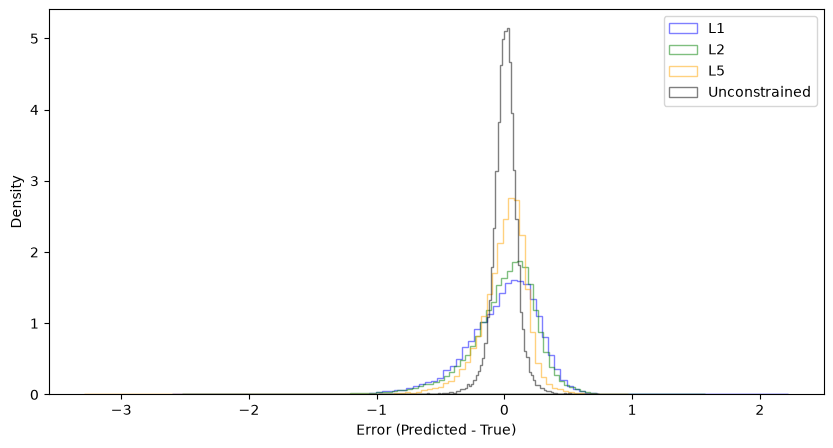

In [23]:
# Plotting the error distributions for the Lipschitz model
# Flatten both sides: predictions are (N, 1), so subtracting a (N,) array would broadcast to (N, N)
y_true = tst_amp_log_scaled.flatten()
L1_errors = L1_predictions.flatten() - y_true
L2_errors = L2_predictions.flatten() - y_true
L5_errors = L5_predictions.flatten() - y_true
Unconstrained_errors = Unconstrained_predictions.flatten() - y_true

plt.figure(figsize=(10, 5))
plt.hist(L1_errors, bins=100, alpha=0.5, label='L1', density=True, histtype='stepfilled', fill=None, edgecolor='blue')
plt.hist(L2_errors, bins=100, alpha=0.5, label='L2', density=True, histtype='stepfilled', fill=None, edgecolor='green')
plt.hist(L5_errors, bins=100, alpha=0.5, label='L5', density=True, histtype='stepfilled', fill=None, edgecolor='orange')
plt.hist(Unconstrained_errors, bins=100, alpha=0.5, label='Unconstrained', density=True, histtype='stepfilled', fill=None, edgecolor='black')
plt.xlabel('Error (Predicted - True)')
plt.ylabel('Density')
#plt.title('Error Distributions for Lipschitz Model')
plt.legend()
#plt.savefig('Plots/Initial_lipNN_error_test.pdf')
plt.show()

We can see that under the same conditions (similar architecture, same optimizer,learning rate, number of epochs, etc.) the unconstrained model performs significantly better than the Lipschitz consstrained model. This could be due to the fact that the Lipschitz constraint is a very strict constraint and reduces the expressivity of the model. by experience, the preprocessing is very important for the outcome of the Lipschitz model.

In order to increase the performance of the Lipschitz model, we can try to increase the Lipschitz constant. This allows for more expressivity of the model, but trades of robustness.

We can approach this even more systematically by testing a finer grid of Lipschitz constants and evaluating the MSE dependence on the Lipschitz constant.


In [24]:
print(np.zeros((3, 4)))

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [25]:
L_arr = np.arange(1, 6, 0.5)  # Array of Lipschitz constants from 0.1 to 5.0
HIDDEN_DIM = 24  # Hidden dimension for the Lipschitz model
NUM_EPOCHS = 100 # Number of epochs for training
N_GROUPS = 4  # Number of groups for the GroupSort activation
MAX_ITER = 50 # Early stopping: stop when the validation loss has not improved for this many epochs
REPEATS = 5  # Number of times to repeat the training for each Lipschitz constant
device = "cuda" if torch.cuda.is_available() else "cpu" # To utilise the best available computing resources
loss_fn = nn.MSELoss()

MSE_loss_arr = np.zeros((len(L_arr), REPEATS))  # Array to store MSE losses for each Lipschitz constant and repeat
std_loss_arr = np.zeros((len(L_arr), REPEATS))  # Array to store standard deviation of losses for each Lipschitz constant

np.random.seed(42)  # Set a seed for reproducibility of the random seeds
seeds = np.random.randint(0, 10000, size=REPEATS)  # Generate random seeds for each repeat

def lipschitz_job(seed=SEED, max_iter=None, **model_kwargs):
    # Settings for training one Lipschitz model in a parallel sweep (see fit_many in train_eval.py)
    return dict(model_cls=LipschitzModel,
                model_kwargs=dict(input_dim=trn_data_scaled.shape[1], output_dim=1, output_bias_init=TRN_AMP_MEAN, **model_kwargs),
                trn_data=trn_tensors, val_data=val_tensors, test_data=test_tensors,
                lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, max_iter=max_iter, batch_size=BATCH_SIZE, seed=int(seed))

# Train REPEATS Lipschitz models (one per seed) for each Lipschitz constant, all in parallel
results = fit_many([lipschitz_job(hidden_dim=HIDDEN_DIM, n_groups=N_GROUPS, lipschitz_bound=float(L), seed=seeds[j], max_iter=MAX_ITER)
                    for L in L_arr for j in range(REPEATS)])

for i, L in enumerate(L_arr):
    for j in range(REPEATS):
        test_predictions = results[i*REPEATS + j]["predictions"]

        # Store the MSE loss for this Lipschitz constant
        mse_loss = loss_fn(torch.tensor(test_predictions), torch.tensor(tst_amp_log_scaled)).item()
        MSE_loss_arr[i, j] += mse_loss  # Accumulate the MSE loss for averaging later

        std_loss = np.std(test_predictions - tst_amp_log_scaled)
        std_loss_arr[i, j] += std_loss  # Accumulate the standard deviation for averaging later


In [26]:
# Average the losses over the repeats
MSE_loss_arr_converged = np.mean(MSE_loss_arr, axis=1)
std_MSE_loss_arr_converged = np.std(MSE_loss_arr, axis=1)
print("MSE Losses for each Lipschitz constant:", MSE_loss_arr_converged)

MSE Losses for each Lipschitz constant: [0.05386156 0.02528397 0.02251654 0.01733118 0.01649792 0.01474338
 0.01270475 0.01258651 0.01378138 0.01304655]


In [27]:
# Training an unconstrained as a baseline
HIDDEN_DIM = 64  # Hidden dimension for the Lipschitz model
NUM_EPOCHS = 50 # Number of epochs for training
loss_fn = nn.MSELoss()

Unconstrained_model = UnconstrainedModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, output_bias_init=TRN_AMP_MEAN).to(device)
optimizer_Unconstrained = torch.optim.Adam(Unconstrained_model.parameters(), lr=LEARNING_RATE) # New optimizer for the new model

train_losses, val_losses = train(Unconstrained_model, trn_loader, val_loader, optimizer_Unconstrained, loss_fn, NUM_EPOCHS, max_iter=NUM_EPOCHS, device=device, train_eval_loader=trn_eval_loader)

preds = predict(Unconstrained_model, test_loader, device=device)

unconstrained_loss = loss_fn(torch.tensor(preds), torch.tensor(tst_amp_log_scaled)).item()


Epoch 1: Train Loss: 0.4622, Val Loss: 0.1177
Epoch 50: Train Loss: 0.0037, Val Loss: 0.0046


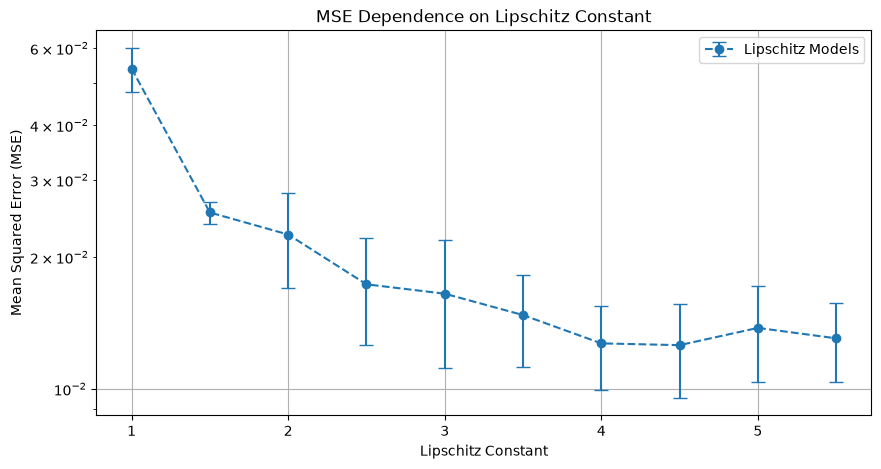

In [28]:
# Plotting the loss dependence on the Lipschitz constant, with errorbars representing the standard deviation of the loss
plt.figure(figsize=(10, 5))
#plt.plot(L_arr, MSE_loss_arr, marker='o', label='MSE loss')
plt.errorbar(L_arr, MSE_loss_arr_converged, yerr=std_MSE_loss_arr_converged, fmt='o--', capsize=5, label='Lipschitz Models')
#plt.axhline(y=unconstrained_loss, color='r', linestyle='--', label='Unconstrained Model')
plt.xlabel('Lipschitz Constant')
plt.ylabel('Mean Squared Error (MSE)')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.savefig('Plots/MSE_dependence_on_Lipschitz_constant.pdf')


plt.title('MSE Dependence on Lipschitz Constant')
plt.show()

## Testing different architectural features
For further testing and insight into the capabilities we want to test different architectural features. We will test the following:
- Different depths
- Different widths
- Different data sizes
- Different Lipschitz constants

### Networks Depths
Using four different depths for testing we evaluate the performance of the Lipschitz constrained model. The depths are 3, 4, 6 and 8 layers. The width is kept constant at 64 neurons per layer. The Lipschitz constant is set to 1.0.

In [29]:
depths = [3, 4, 6, 8, 14]
predictions_dict_depth = {}  # Dictionary to store predictions for each depth
LEARNING_RATE = 0.001
HIDDEN_DIM = 64
NUM_EPOCHS = 50
loss_fn = nn.MSELoss()
device = "cuda" if torch.cuda.is_available() else "cpu" # To utilise the best available computing resources

# Train one Lipschitz model per depth, in parallel.
# The hidden layers start from a (noisy) identity: with the default initialization the signal shrinks in every
# normalized layer, and the deepest networks (depth > ~10) do not train at all once the output offset is initialized.
results = fit_many([lipschitz_job(hidden_dim=HIDDEN_DIM, lipschitz_bound=1.0, depth=depth, hidden_init="identity") for depth in depths])

for depth, result in zip(depths, results):
    predictions_dict_depth[depth] = result["predictions"]

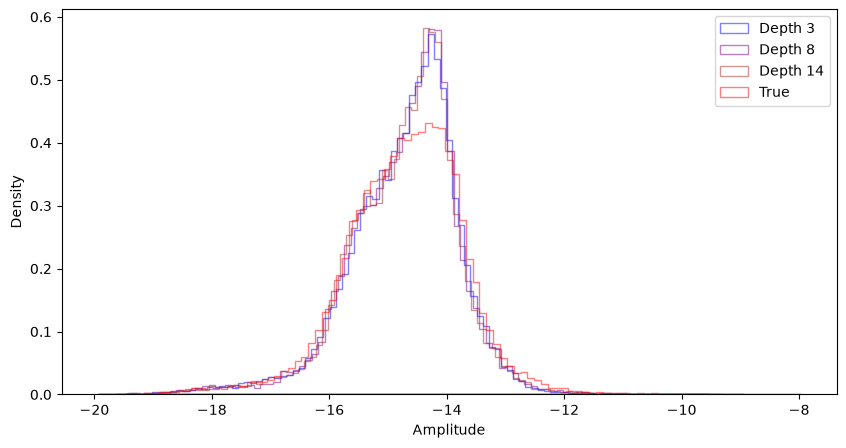

In [30]:
# Plotting
colors = ['blue', 'green', 'orange', 'purple', 'brown']  # Define colors for each depth
plt.figure(figsize=(10, 5))
for depth, predictions in predictions_dict_depth.items():
    if depth == 4 or depth == 6:  # Only plot for depths 4 and 6
        continue  # Skip plotting for depths 4 and 6
    plt.hist(predictions, bins=100, alpha=0.5, label=f'Depth {depth}', density=True, histtype='stepfilled', fill=None, edgecolor=colors[depths.index(depth)])
plt.hist(tst_amp_log_scaled, bins=100, alpha=0.5, label='True', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.xlabel('Amplitude')
plt.ylabel('Density')
plt.legend()
plt.savefig('Plots/Depths_lipNN_test.pdf')

plt.show()

In [31]:
# Test with a very deep model
depth = 20
model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=1.0, depth=depth,
                       output_bias_init=TRN_AMP_MEAN, hidden_init="identity").to(device)

train_losses, val_losses = train(model=model,
                                 train_loader=trn_loader,
                                 val_loader=val_loader,
                                 train_eval_loader=trn_eval_loader,
                                 optimizer=torch.optim.Adam(model.parameters(), lr=LEARNING_RATE),
                                 loss_fn=loss_fn,
                                 num_epochs=NUM_EPOCHS,
                                 max_iter=NUM_EPOCHS, # No early stopping
                                 device=device)

deep_predictions = predict(model, test_loader, device=device)

Epoch 1: Train Loss: 1.0877, Val Loss: 0.4374
Epoch 50: Train Loss: 0.0640, Val Loss: 0.0675


In [32]:
# adding to the pred dictionary
predictions_dict_depth[depth] = deep_predictions

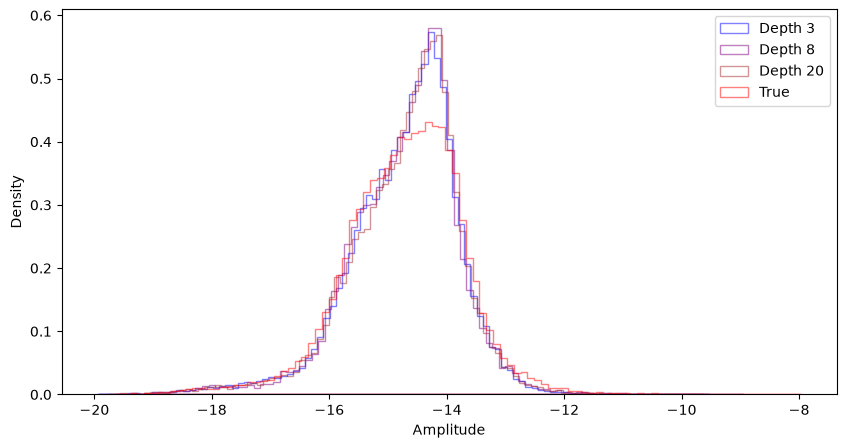

In [33]:
# Plotting specific depths
chosen_depths = [3, 8, 20]  # Include the very deep model, and the shallowest
colors = ['blue', 'green', 'orange', 'purple', 'brown']  # Define colors for each depth

plt.figure(figsize=(10, 5))
for depth in chosen_depths:
    predictions = predictions_dict_depth[depth]
    plt.hist(predictions, bins=100, alpha=0.5, label=f'Depth {depth}', density=True, histtype='stepfilled', fill=None, edgecolor=colors[depths.index(depth) if depth in depths else -1])
plt.hist(tst_amp_log_scaled, bins=100, alpha=0.5, label='True', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.xlabel('Amplitude')
plt.ylabel('Density')
plt.legend()
plt.savefig('Plots/Chosen_Depths_lipNN_test.pdf')
plt.show()

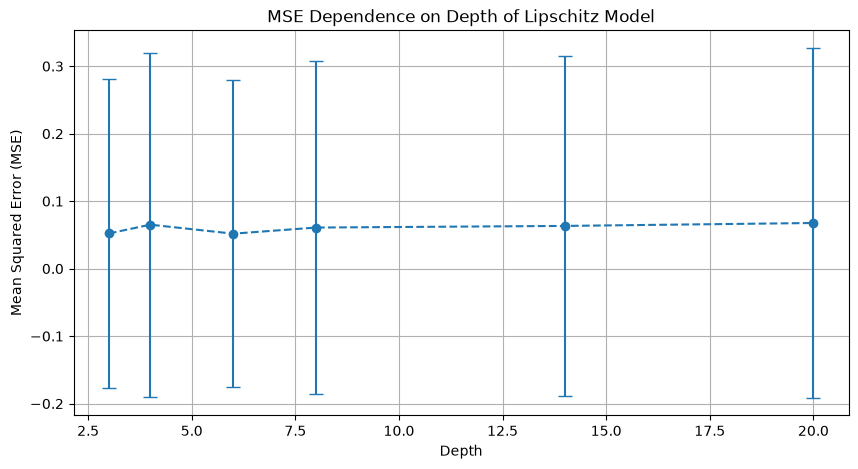

In [34]:
# Calculating and plotting the errors for the chosen depths
errors_dict = {}
all_depths = predictions_dict_depth.keys()  # Get all depths including the very deep model
std_errors_dict = {}
for depth in all_depths:
    predictions = predictions_dict_depth[depth]
    errors = nn.MSELoss()(torch.tensor(predictions), torch.tensor(tst_amp_log_scaled)).item()
    std_error = np.std(predictions - tst_amp_log_scaled)
    errors_dict[depth] = errors
    std_errors_dict[depth] = std_error

# Plotting the errors for all depths
plt.figure(figsize=(10, 5))

plt.errorbar(list(errors_dict.keys()), list(errors_dict.values()), yerr=list(std_errors_dict.values()), fmt='o--', capsize=5, label='MSE with Std Dev')
plt.xlabel('Depth')
plt.ylabel('Mean Squared Error (MSE)')

plt.grid(True)
plt.savefig('Plots/MSE_dependence_on_depth.pdf')
plt.title('MSE Dependence on Depth of Lipschitz Model')

plt.show()

### Network widths
Using four different widths for testing we evaluate the performance of the Lipschitz constrained model. The widths are 32, 64, 128 and 256 neurons per layer. The depth is kept constant at 3 layers. The Lipschitz constant is set to 1.0.

In [35]:
depth = 3
widths = [32, 64, 128, 256]
predictions_dict_width = {}  # Dictionary to store predictions for each depth
LEARNING_RATE = 0.001
NUM_EPOCHS = 100
loss_fn = nn.MSELoss()

# Train one Lipschitz model per width, in parallel
results = fit_many([lipschitz_job(hidden_dim=width, lipschitz_bound=1.0, depth=depth) for width in widths])

for width, result in zip(widths, results):
    predictions_dict_width[width] = result["predictions"]

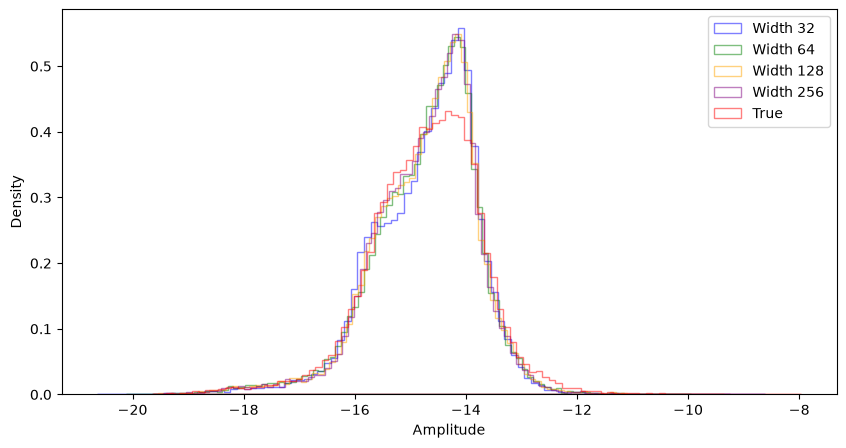

In [36]:
# Plotting the predicted vs true amplitudes for different depths
colors = ['blue', 'green', 'orange', 'purple']  # Define colors for each depth
plt.figure(figsize=(10, 5))
for width, predictions in predictions_dict_width.items():
    plt.hist(predictions, bins=100, alpha=0.5, label=f'Width {width}', density=True, histtype='stepfilled', fill=None, edgecolor=colors[widths.index(width)])
plt.hist(tst_amp_log_scaled, bins=100, alpha=0.5, label='True', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.xlabel('Amplitude')
plt.ylabel('Density')
plt.legend()
plt.savefig('Plots/Widths_lipNN_test.pdf')
plt.show()

# Certification

Certification at inference is an important motivation of Lipschitz networks as they can quantify robustness of the models. For classification problems this is straight forward (given that one knows the norm being optimized for). For regression problems this is an open question, here we will try to use the certification methods provided by the classification tasks and instead give a margin of tolerable data drift.

For classification problems, the certification for a network optimized with the $l_2$ norm is defined as 
$$
r = \frac{m(x)}{L\sqrt{2}},
$$
where $m(x)$ is the margin of the prediction and $L$ is the Lipschitz constant. The margin is defined as the magnitude of the difference between the largest logit and the second largest logit.

FIGURE THIS OUT LATER